# Prefect Orchestration. Multi-crew flow with branching

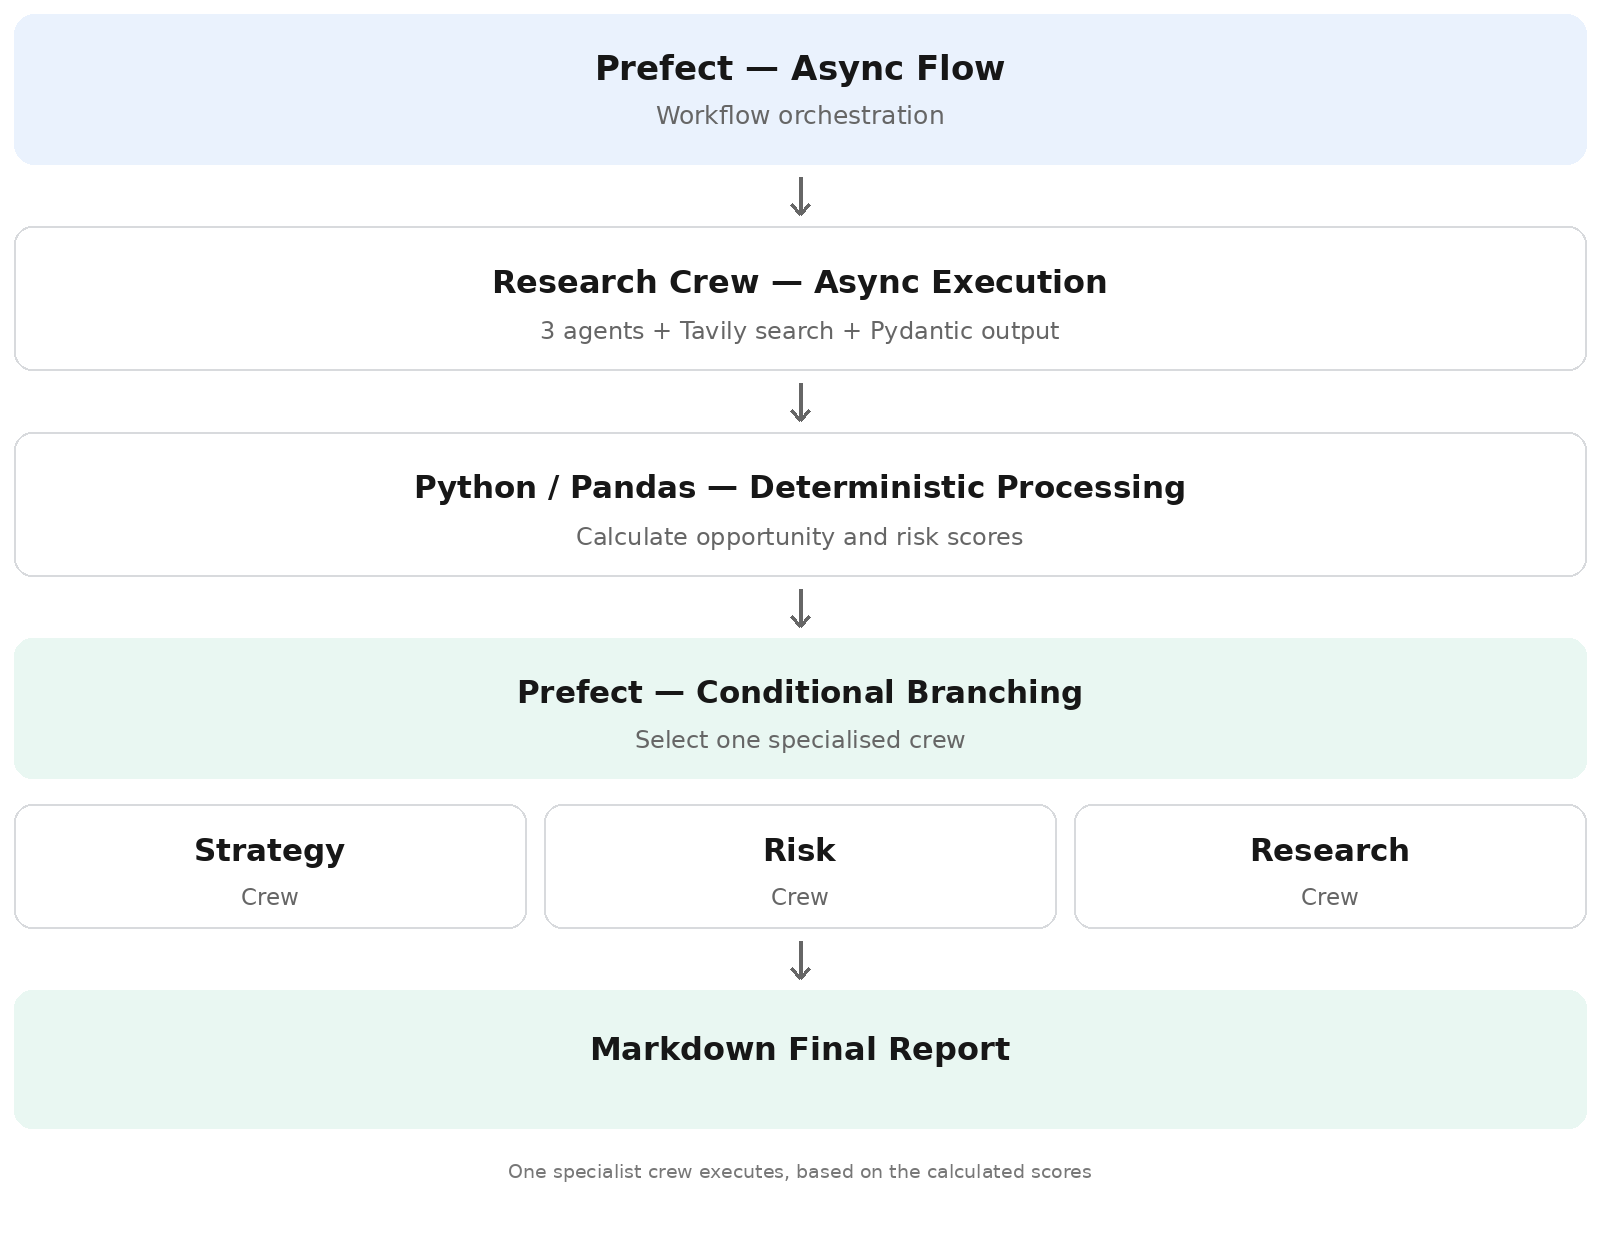

In [ ]:
!uv pip install "crewai[litellm]" crewai_tools

In [ ]:
!uv pip install tavily-python

In [ ]:
!uv pip install prefect

In [ ]:
!uv pip install tavily-python

In [ ]:
# Warning control
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import os
from google.colab import userdata

os.environ["OPENROUTER_API_KEY"] = userdata.get('OPENROUTER_API_KEY')
os.environ["OPENAI_API_BASE"] = "https://openrouter.ai/api/v1"

In [ ]:
# from crewai import LLM

# llm = LLM(
#     model="openrouter/openai/gpt-4o-mini",
#     temperature=0.1
# )

In [ ]:
# from google.colab import userdata
# import os
# from crewai import LLM

# os.environ['GEMINI_API_KEY']=userdata.get('GEMINI_API_KEY')

# llm = LLM(
#     model="gemini/gemini-3.6-flash"
# )

In [ ]:
# from google.colab import userdata
# import os
# from crewai import LLM

# os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

# llm = LLM(
#     model="gpt-4o-mini",
#     temperature=0.1
# )

In [ ]:
os.environ['TAVILY_API_KEY']=userdata.get('TAVILY_API_KEY')

In [ ]:
from crewai_tools import TavilySearchTool

# Initialise Tavily search
search_tool = TavilySearchTool(
    search_depth="advanced",
    max_results=5
)

In [ ]:
from crewai import Agent, Task, Crew

In [ ]:
from pydantic import BaseModel, Field

In [ ]:
class MarketResearch(BaseModel):

    market_growth_pct: float

    demand_index: float = Field(ge=0, le=100)

    competition_intensity: float = Field(ge=0, le=100)

    regulatory_risk: float = Field(ge=0, le=100)

    evidence_count: int

    summary: str

# Market Research Crew

In [ ]:
market_researcher = Agent(
    role="Market Researcher",
    goal="Research market growth and demand.",
    backstory="""
    You are an experienced European market research specialist.
    You identify market trends, growth opportunities and
    credible information sources.
    """,
    tools=[search_tool],
    llm=llm,
    verbose=True
)


competitor_analyst = Agent(
    role="Competitor Analyst",
    goal="Investigate the competitive environment.",
    backstory="""
    You specialize in competitive intelligence.
    You identify major competitors, market concentration
    and competitive pressures.
    """,
    tools=[search_tool],
    llm=llm,
    verbose=True
)


market_assessment_analyst = Agent(
    role="Market Assessment Analyst",
    goal="Consolidate research into a structured assessment.",
    backstory="""
    You are a senior market assessment consultant.
    You combine market research and competitor intelligence
    into evidence-based market assessments.
    """,
    llm=llm,
    verbose=True
)

In [ ]:
research_task = Task(
    description="""
    Research the market in {country} for the industry {industry}.

    Investigate:
    - Market size and growth
    - Market demand
    - Recent developments
    - Relevant market sources

    Prioritize credible and recent sources.
    """,
    expected_output="Market research findings with source URLs and evidence.",
    agent=market_researcher
)


competition_task = Task(
    description="""
    Investigate the competitive environment in {country}
    for {industry}.

    Use the market research findings from the previous task.

    Evaluate:
    - Major competitors
    - Competitive intensity (0-100)
    - Market concentration
    - Competitive barriers

    Support your assessment with evidence.
    """,
    expected_output="Competitive intelligence assessment.",
    agent=competitor_analyst,
    context=[research_task]
)


assessment_task = Task(
    description="""
    Consolidate the market research and competitive analysis.

    Produce a structured MarketResearch object containing:

    - market_growth_pct
    - demand_index (0-100)
    - competition_intensity (0-100)
    - regulatory_risk (0-100)
    - evidence_count
    - summary

    Estimate regulatory risk based on available research.
    Use evidence from the preceding tasks.
    Do not invent statistics or sources.
    """,
    expected_output="Structured market assessment.",
    agent=market_assessment_analyst,
    context=[research_task, competition_task],
    output_pydantic=MarketResearch
)

In [ ]:
market_research_crew = Crew(
    agents=[
        market_researcher,
        competitor_analyst,
        market_assessment_analyst
    ],
    tasks=[
        research_task,
        competition_task,
        assessment_task
    ],
    verbose=True
)

# Strategic Planning Crew

This crew executes only when the opportunity score is sufficiently high and the risk score is acceptable.

In [ ]:
market_entry_strategist = Agent(
    role="Market Entry Strategist",
    goal="Develop a market entry strategy.",
    backstory="""
    You are an international business strategist
    specializing in European market expansion.
    """,
    llm=llm,
    verbose=True
)


business_development_analyst = Agent(
    role="Business Development Analyst",
    goal="Identify customers, partnerships and growth opportunities.",
    backstory="""
    You specialize in commercial development,
    market positioning and business opportunities.
    """,
    llm=llm,
    verbose=True
)


strategy_consultant = Agent(
    role="Strategy Consultant",
    goal="Develop actionable market entry recommendations.",
    backstory="""
    You are a senior strategy consultant who transforms
    market intelligence into practical implementation plans.
    """,
    llm=llm,
    verbose=True
)

In [ ]:
entry_strategy_task = Task(
    description="""
    Develop a market entry strategy for {industry}
    in {country}.

    Use the following market assessment:

    {market_data}

    Evaluate market attractiveness and positioning.
    """,
    expected_output="A proposed market entry strategy.",
    agent=market_entry_strategist
)


opportunity_task = Task(
    description="""
    Based on the market entry strategy, identify:

    - Potential customer segments
    - Business partnerships
    - Commercial opportunities
    - Competitive advantages

    Use evidence from the previous task.
    """,
    expected_output="Business development and opportunity analysis.",
    agent=business_development_analyst,
    context=[entry_strategy_task]
)


strategy_recommendation_task = Task(
    description="""
    Consolidate the previous analyses.

    Develop a final market entry recommendation.

    Include:
    - Recommended entry approach
    - Priority customer segments
    - Potential partnerships
    - Implementation priorities
    - Expected challenges

    Clearly distinguish evidence from assumptions.
    """,
    expected_output="A comprehensive market entry recommendation in Markdown.",
    agent=strategy_consultant,
    context=[entry_strategy_task, opportunity_task]
)

In [ ]:
strategy_crew = Crew(
    agents=[
        market_entry_strategist,
        business_development_analyst,
        strategy_consultant
    ],
    tasks=[
        entry_strategy_task,
        opportunity_task,
        strategy_recommendation_task
    ],
    verbose=True
)

# Risk Assessment Crew

This crew executes when the market risk score reaches the predefined threshold.

In [ ]:
regulatory_risk_analyst = Agent(
    role="Regulatory Risk Analyst",
    goal="Investigate regulatory and compliance risks.",
    backstory="""
    You specialize in European regulatory environments,
    compliance requirements and market entry restrictions.
    """,
    tools=[search_tool],
    llm=llm,
    verbose=True
)


competitive_risk_analyst = Agent(
    role="Competitive Risk Analyst",
    goal="Evaluate competitive and commercial risks.",
    backstory="""
    You are an experienced business risk analyst
    specializing in competitive threats and market uncertainty.
    """,
    tools=[search_tool],
    llm=llm,
    verbose=True
)


risk_management_consultant = Agent(
    role="Risk Management Consultant",
    goal="Develop risk mitigation recommendations.",
    backstory="""
    You are a senior risk management consultant
    specializing in business expansion.
    """,
    llm=llm,
    verbose=True
)

In [ ]:
regulatory_task = Task(
    description="""
    Investigate regulatory risks for {industry}
    in {country}.

    Use the market assessment:

    {market_data}

    Identify relevant regulations, compliance obligations
    and potential restrictions.
    """,
    expected_output="Regulatory risk assessment.",
    agent=regulatory_risk_analyst
)


competitive_risk_task = Task(
    description="""
    Evaluate competitive and commercial risks.

    Consider the market assessment and regulatory findings.

    Identify:
    - Competitive threats
    - Market entry barriers
    - Commercial uncertainties
    - Potential financial exposure
    """,
    expected_output="Competitive and commercial risk analysis.",
    agent=competitive_risk_analyst,
    context=[regulatory_task]
)


risk_recommendation_task = Task(
    description="""
    Consolidate the regulatory and competitive risk assessments.

    Prepare a risk management report including:

    - Major identified risks
    - Risk severity
    - Potential consequences
    - Mitigation measures
    - Recommended actions

    Distinguish documented risks from potential risks.
    """,
    expected_output="A comprehensive risk assessment in Markdown.",
    agent=risk_management_consultant,
    context=[regulatory_task, competitive_risk_task]
)

In [ ]:
risk_crew = Crew(
    agents=[
        regulatory_risk_analyst,
        competitive_risk_analyst,
        risk_management_consultant
    ],
    tasks=[
        regulatory_task,
        competitive_risk_task,
        risk_recommendation_task
    ],
    verbose=True
)

# Further Investigation Crew
This crew executes when there is insufficient evidence or the market opportunity does not meet the decision threshold.

In [ ]:
evidence_researcher = Agent(
    role="Evidence Researcher",
    goal="Identify gaps in available market evidence.",
    backstory="""
    You are an investigative market researcher
    specializing in evidence quality and source validation.
    """,
    tools=[search_tool],
    llm=llm,
    verbose=True
)


market_validation_analyst = Agent(
    role="Market Validation Analyst",
    goal="Determine what additional information is required.",
    backstory="""
    You specialize in market validation and
    identifying uncertainty in business research.
    """,
    tools=[search_tool],
    llm=llm,
    verbose=True
)


research_coordinator = Agent(
    role="Research Coordinator",
    goal="Develop a prioritized investigation plan.",
    backstory="""
    You are a senior research coordinator.
    You design structured investigations to close
    evidence gaps and support business decisions.
    """,
    llm=llm,
    verbose=True
)

In [ ]:
evidence_gap_task = Task(
    description="""
    Examine the available market assessment:

    {market_data}

    Identify:
    - Missing evidence
    - Uncertain findings
    - Weak or incomplete information
    - Areas requiring further research
    """,
    expected_output="A list of evidence gaps and research weaknesses.",
    agent=evidence_researcher
)


validation_task = Task(
    description="""
    Examine the evidence gaps identified in the previous task.

    Determine what additional information is required
    to assess the market properly.

    Identify specific research questions and potential sources.
    """,
    expected_output="A market validation assessment.",
    agent=market_validation_analyst,
    context=[evidence_gap_task]
)


investigation_plan_task = Task(
    description="""
    Prepare a prioritized further investigation plan.

    Include:
    - Research questions
    - Information requirements
    - Recommended sources
    - Validation methods
    - Priority of each investigation activity

    Do not claim that additional research has already been completed.
    """,
    expected_output="A structured market investigation plan in Markdown.",
    agent=research_coordinator,
    context=[evidence_gap_task, validation_task]
)

In [ ]:
investigation_crew = Crew(
    agents=[
        evidence_researcher,
        market_validation_analyst,
        research_coordinator
    ],
    tasks=[
        evidence_gap_task,
        validation_task,
        investigation_plan_task
    ],
    verbose=True
)

# Prefect Tasks

In [ ]:
from prefect import task, flow
import pandas as pd
import json
from pathlib import Path

In [ ]:
# ================================================
# TASK 1: MARKET RESEARCH
# ================================================

@task(name="Market Research", retries=1)
async def run_market_research(country, industry):

    result = await market_research_crew.kickoff_async(
        inputs={
            "country": country,
            "industry": industry
        }
    )

    if result.pydantic is None:
        raise ValueError(
            "Market Research Crew did not return valid Pydantic output."
        )

    return result.pydantic.model_dump()


# ================================================
# TASK 2: DETERMINISTIC SCORING
# ================================================

@task(name="Calculate Market Scores")
async def calculate_scores(data):

    # Validate incoming data
    market = MarketResearch.model_validate(data)

    # Use Pandas for deterministic calculations
    df = pd.DataFrame([market.model_dump()])

    # Normalise market growth to a 0-100 scale.
    # Growth above 20% receives the maximum score.
    df["growth_score"] = (
        df["market_growth_pct"].clip(lower=0, upper=20) / 20
    ) * 100

    # Opportunity score
    df["opportunity_score"] = (
        df["growth_score"] * 0.40
        + df["demand_index"] * 0.35
        + (100 - df["competition_intensity"]) * 0.25
    )

    # Risk score
    df["risk_score"] = (
        df["regulatory_risk"] * 0.60
        + df["competition_intensity"] * 0.40
    )

    # Return a normal Python dictionary
    scores = df.iloc[0].to_dict()

    return {
        key: (
            round(float(value), 2)
            if isinstance(value, (int, float))
            else value
        )
        for key, value in scores.items()
    }


# ================================================
# TASK 3: SELECT DECISION BRANCH
# ================================================

@task(name="Select Decision Branch")
async def determine_branch(data):

    if data["evidence_count"] < 5:
        branch = "investigation"

    elif data["risk_score"] >= 60:
        branch = "risk"

    elif data["opportunity_score"] >= 65:
        branch = "strategy"

    else:
        branch = "investigation"

    return branch


# ================================================
# TASK 4: STRATEGIC PLANNING
# ================================================

@task(name="Strategic Planning")
async def run_strategy(country, industry, data):

    result = await strategy_crew.kickoff_async(
        inputs={
            "country": country,
            "industry": industry,
            "market_data": json.dumps(data, indent=2)
        }
    )

    return result.raw


# ================================================
# TASK 5: RISK ASSESSMENT
# ================================================

@task(name="Risk Assessment")
async def run_risk_assessment(country, industry, data):

    result = await risk_crew.kickoff_async(
        inputs={
            "country": country,
            "industry": industry,
            "market_data": json.dumps(data, indent=2)
        }
    )

    return result.raw


# ================================================
# TASK 6: FURTHER INVESTIGATION
# ================================================

@task(name="Further Investigation")
async def run_investigation(country, industry, data):

    result = await investigation_crew.kickoff_async(
        inputs={
            "country": country,
            "industry": industry,
            "market_data": json.dumps(data, indent=2)
        }
    )

    return result.raw


# ================================================
# TASK 7: SAVE FINAL REPORT
# ================================================

@task(name="Save Final Report")
async def save_report(report, branch, data, country, industry):

    final_report = f"""
# Market Intelligence Report

## Market

- **Country:** {country}
- **Industry:** {industry}
- **Selected workflow:** {branch}

## Market Research Summary

{data["summary"]}

## Market Indicators

| Indicator | Value |
|---|---:|
| Market growth | {data["market_growth_pct"]}% |
| Demand index | {data["demand_index"]} |
| Competition intensity | {data["competition_intensity"]} |
| Regulatory risk | {data["regulatory_risk"]} |
| Evidence count | {data["evidence_count"]} |

## Calculated Scores

| Score | Value |
|---|---:|
| Growth score | {data["growth_score"]} |
| Opportunity score | {data["opportunity_score"]} |
| Risk score | {data["risk_score"]} |

## Decision

The Prefect workflow selected the **{branch}** branch
based on the calculated market indicators and evidence availability.

## Specialist Crew Analysis

{report}

---

*Generated using Prefect, CrewAI, Pandas and Tavily.*
"""

    filename = f"market_assessment_{branch}.md"

    Path(filename).write_text(
        final_report,
        encoding="utf-8"
    )

    return final_report

In [ ]:
# ================================================
# MAIN PREFECT FLOW
# ================================================

@flow(name="Market Intelligence Pipeline")
async def market_intelligence_pipeline(country, industry):

    print("\n1. Starting market research...")

    # Step 1: Research
    research = await run_market_research(
        country,
        industry
    )

    print("\n2. Calculating market scores...")

    # Step 2: Deterministic processing
    scores = await calculate_scores(research)

    print("\nMarket Scores:")
    print(f"Opportunity: {scores['opportunity_score']}")
    print(f"Risk: {scores['risk_score']}")
    print(f"Evidence: {scores['evidence_count']}")

    print("\n3. Selecting workflow branch...")

    # Step 3: Branch selection
    branch = await determine_branch(scores)

    print(f"\nSelected branch: {branch.upper()}")

    print("\n4. Executing selected specialist crew...")

    # Step 4: Execute only one branch
    if branch == "strategy":

        report = await run_strategy(
            country,
            industry,
            scores
        )

    elif branch == "risk":

        report = await run_risk_assessment(
            country,
            industry,
            scores
        )

    else:

        report = await run_investigation(
            country,
            industry,
            scores
        )

    print("\n5. Generating final Markdown report...")

    # Step 5: Save report
    final_report = await save_report(
        report,
        branch,
        scores,
        country,
        industry
    )

    return final_report

## Run Prefect server in Colab

In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared
!chmod +x /usr/local/bin/cloudflared

In [ ]:
!nohup cloudflared tunnel --url http://127.0.0.1:4200 --no-autoupdate > /tmp/cloudflared.log 2>&1 &

In [ ]:
import os
import re
import time

public_url = None

for _ in range(30):
    if os.path.exists("/tmp/cloudflared.log"):
        with open("/tmp/cloudflared.log") as f:
            log = f.read()

        match = re.search(
            r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
            log
        )

        if match:
            public_url = match.group(0)
            break

    time.sleep(1)

if public_url:
    print("Prefect Dashboard URL:", public_url)
else:
    print("Tunnel URL not found. Check /tmp/cloudflared.log")

In [ ]:
import os
import subprocess
import time
import requests

# Local API for the Colab workflow
os.environ["PREFECT_API_URL"] = "http://127.0.0.1:4200/api"

# Public API address for the dashboard
os.environ["PREFECT_SERVER_UI_API_URL"] = public_url + "/api"

# Allow the server to accept connections through the tunnel
os.environ["PREFECT_SERVER_API_HOST"] = "0.0.0.0"

# Start dedicated Prefect server
server_log = open("/tmp/prefect-server.log", "w")

prefect_server = subprocess.Popen(
    [
        "prefect", "server", "start",
        "--host", "0.0.0.0",
        "--port", "4200"
    ],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

# Wait until the API is available
for _ in range(60):
    try:
        response = requests.get(
            "http://127.0.0.1:4200/api/health",
            timeout=2
        )

        if response.status_code == 200:
            print("Prefect server is running!")
            break

    except requests.RequestException:
        time.sleep(2)
else:
    print("Server did not become ready. Check /tmp/prefect-server.log")

In [ ]:
from IPython.display import display, HTML

display(HTML(
    f'<a href="{public_url}" target="_blank">'
    f'Open Prefect Dashboard</a>'
))

# Run the flow

In [ ]:
result = await market_intelligence_pipeline(
    country="Germany",
    industry="Artificial Intelligence"
)

In [ ]:
from IPython.display import display, Markdown

display(Markdown(result))

# Stop Prefect server

In [ ]:
# Stop Prefect server
prefect_server.terminate()
prefect_server.wait(timeout=5)

# Stop Cloudflare tunnel
!pkill -f cloudflared

print("Prefect server and Cloudflare tunnel stopped.")